In [1]:
import kagglehub

# Download the latest version of the dataset
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

c:\Users\elbgr\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\elbgr\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


In [2]:
import os

# Show the downloaded files:
print("Dataset contents")
print(os.listdir(path))


Dataset contents
['amz_uk_price_prediction_dataset.csv']


In [3]:
import pandas as pd

df = pd.read_csv(f"{path}/amz_uk_price_prediction_dataset.csv")
print(df.head())

   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...    4.6   

   reviews  price  isBestSeller  boughtInLastMonth        category  
0    15308  21.99         False                  0  Hi-Fi Speakers  
1    98099  23.99          True                  0  Hi-Fi Speakers  
2    15308  21.99         False                  0  Hi-Fi Speakers  
3     7205  31.99         False                  0  Hi-Fi Speakers  
4     1881  17.99         False                  0  Hi-Fi Speakers  


In [4]:
#INITIAL EXPLORATION OF THE DATASET:

# Retrieving the number of rows and columns in the dataframe
print(df.shape)

# Displaying the data types of each column in the dataframe
print(df.dtypes)

# Display the first few rows of the dataset
df.head()

(2443651, 9)
uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [5]:
df_numerical=df.select_dtypes("number")
df_object=df.select_dtypes("object")

# Extracting column names with numerical data types from the dataframe
print(df_numerical.columns)
print(df_object.columns)

# Counting and sorting the unique values for each numerical column in descending order
print(df_numerical.nunique().sort_values(ascending=False))
# stars is categorical because is a rating 
print(df.select_dtypes("object").nunique().sort_values(ascending=False))

#category is categorical 

#there is only 1 column left 'isbestseller' that is a boolean

Index(['uid', 'stars', 'reviews', 'price', 'boughtInLastMonth'], dtype='object')
Index(['asin', 'title', 'category'], dtype='object')
uid                  2443651
price                  82916
reviews                19446
stars                     42
boughtInLastMonth         25
dtype: int64
asin        2222742
title       2077591
category        296
dtype: int64


In [6]:
# Checking for missing data
df.isnull().sum().sort_values(ascending=False)

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [7]:
# Identifying columns in the dataframe where over 80% of the values are missing
df.columns[df.isnull().mean() > 0.8]

Index([], dtype='object')

In [8]:
# Filtering out columns in the dataframe where more than 80% of the values are missing
df = df[df.columns[df.isnull().mean() < 0.8]]

In [9]:
# Removing the "Id" column from the dataframe
df.drop("uid", inplace=True, axis=1)

## **Bivariate Analysis:**

## **Part 1:** Analyzing Best-Seller Trends Across Product Categories

**Objective:** Understand the relationship between product categories and their best-seller status.

**1.Crosstab Analysis:**

- Create a crosstab between the product category and the isBestSeller status.
- Are there categories where being a best-seller is more prevalent?

 *Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*

**2.Statistical Tests:**

- Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
- Compute Cramér's V to understand the strength of association between best-seller status and category.

**3.Visualizations:**

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.


In [10]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])

crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency

In [12]:
crosstab_percentaje = pd.crosstab(df["category"], df["isBestSeller"], normalize='index') * 100

crosstab_percentaje_sorted = crosstab_percentaje.sort_values(by=True, ascending=False)

crosstab_percentaje_sorted

isBestSeller,False,True
category,,
Grocery,94.186533,5.813467
Smart Home Security & Lighting,94.230769,5.769231
Health & Personal Care,94.231372,5.768628
Mobile Phone Accessories,95.752896,4.247104
Power & Hand Tools,96.466105,3.533895
...,...,...
Bedding Collections,100.000000,0.000000
CPUs,100.000000,0.000000
"CD, Disc & Tape Players",100.000000,0.000000


In [13]:
#The function chi2_contingency() returns four values:

# 1.The chi-square statistic

# 2.The p-value

# 3.The degrees of freedom

# 4.The expected frequencies

#However, in this analysis only the chi-square statistic and the p-value are needed.
#The remaining two outputs are irrelevant for the current task.

#In Python, the underscore _ is commonly used as a placeholder variable to indicate that a returned value is being intentionally ignored.
#This is a standard convention and helps keep the code clean and readable by avoiding unnecessary variables.

chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value

(np.float64(36540.20270061387), np.float64(0.0))

In [ ]:
#Cramers V to understand the strength association.
from scipy.stats.contingency import association

# Computing the association between variables in 'crosstab_result' using the "cramer" method
association(crosstab_result, method="cramer")




0.1222829439760564

<Axes: xlabel='category'>

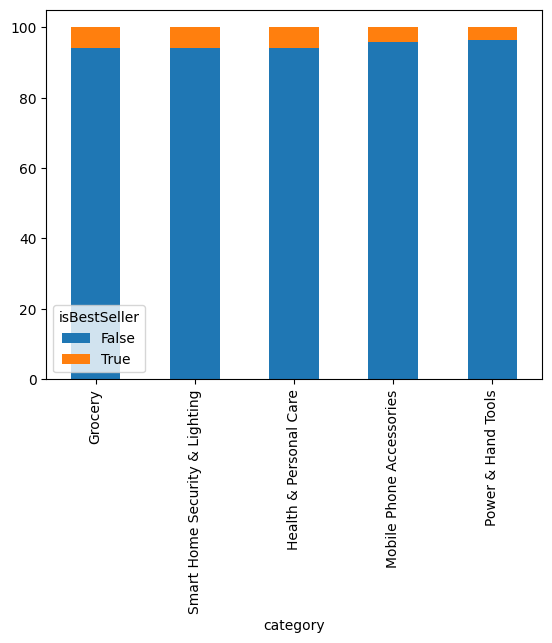

In [22]:
crosstab_percentaje_sorted.head(5).plot(kind="bar", stacked=True)

## **Part 2:** Exploring Product Prices and Ratings Across Categories and Brands

**Objective:** Investigate how different product categories influence product prices.

**0.Preliminary Step: Remove outliers in product prices.**

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

 *Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

**1.Violin Plots:**

Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
Which product category tends to have the highest median price? Don't filter here by top categories.

**2.Bar Charts:**

Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
Which product category commands the highest average price? Don't filter here by top categories.

**3.Box Plots:**

Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.

Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [15]:
#Preliminary Step: Remove outliers in product prices.

# Calculate Q1, Q3 and IQR for product prices
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Define the lower and upper bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Remove outliers
df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

df_no_outliers.head()


,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


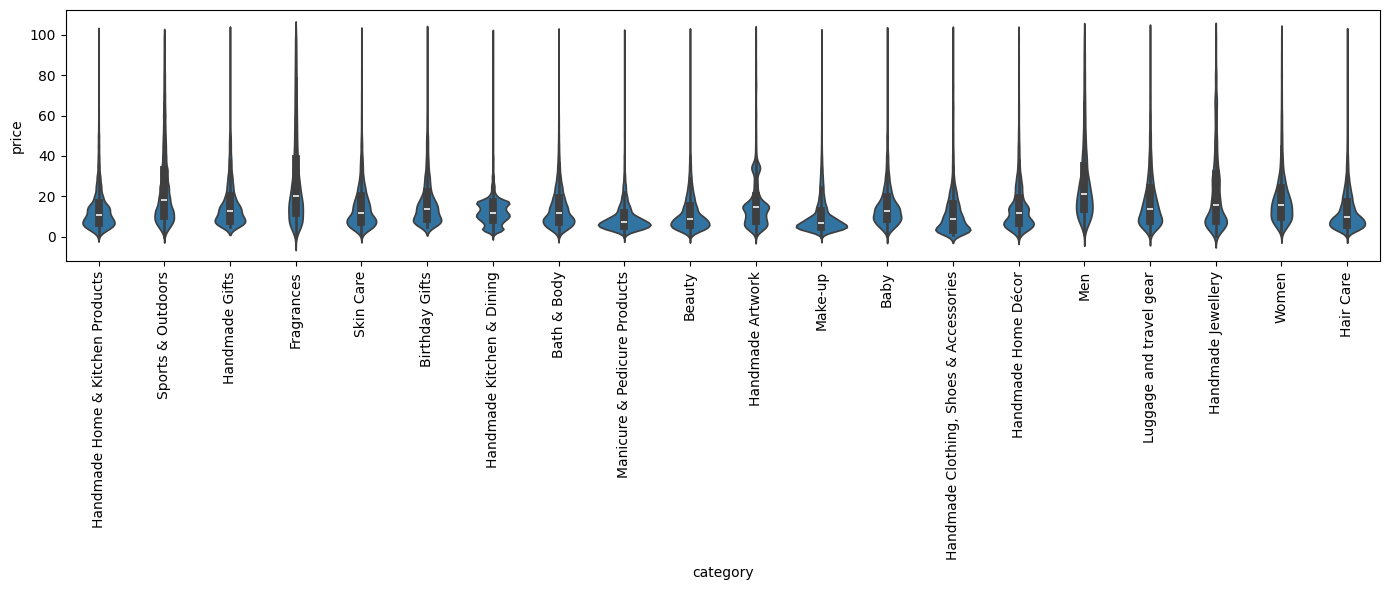

In [16]:
#1.Violin Plots:
top_categories = df_no_outliers['category'].value_counts().head(20).index

df_top_cat = df_no_outliers[df_no_outliers['category'].isin(top_categories)]

plt.figure(figsize=(14, 6))
sns.violinplot(data=df_top_cat, x='category', y='price')
plt.xticks(rotation=90)
plt.tight_layout()   #adjust the elements on the graph
plt.show()




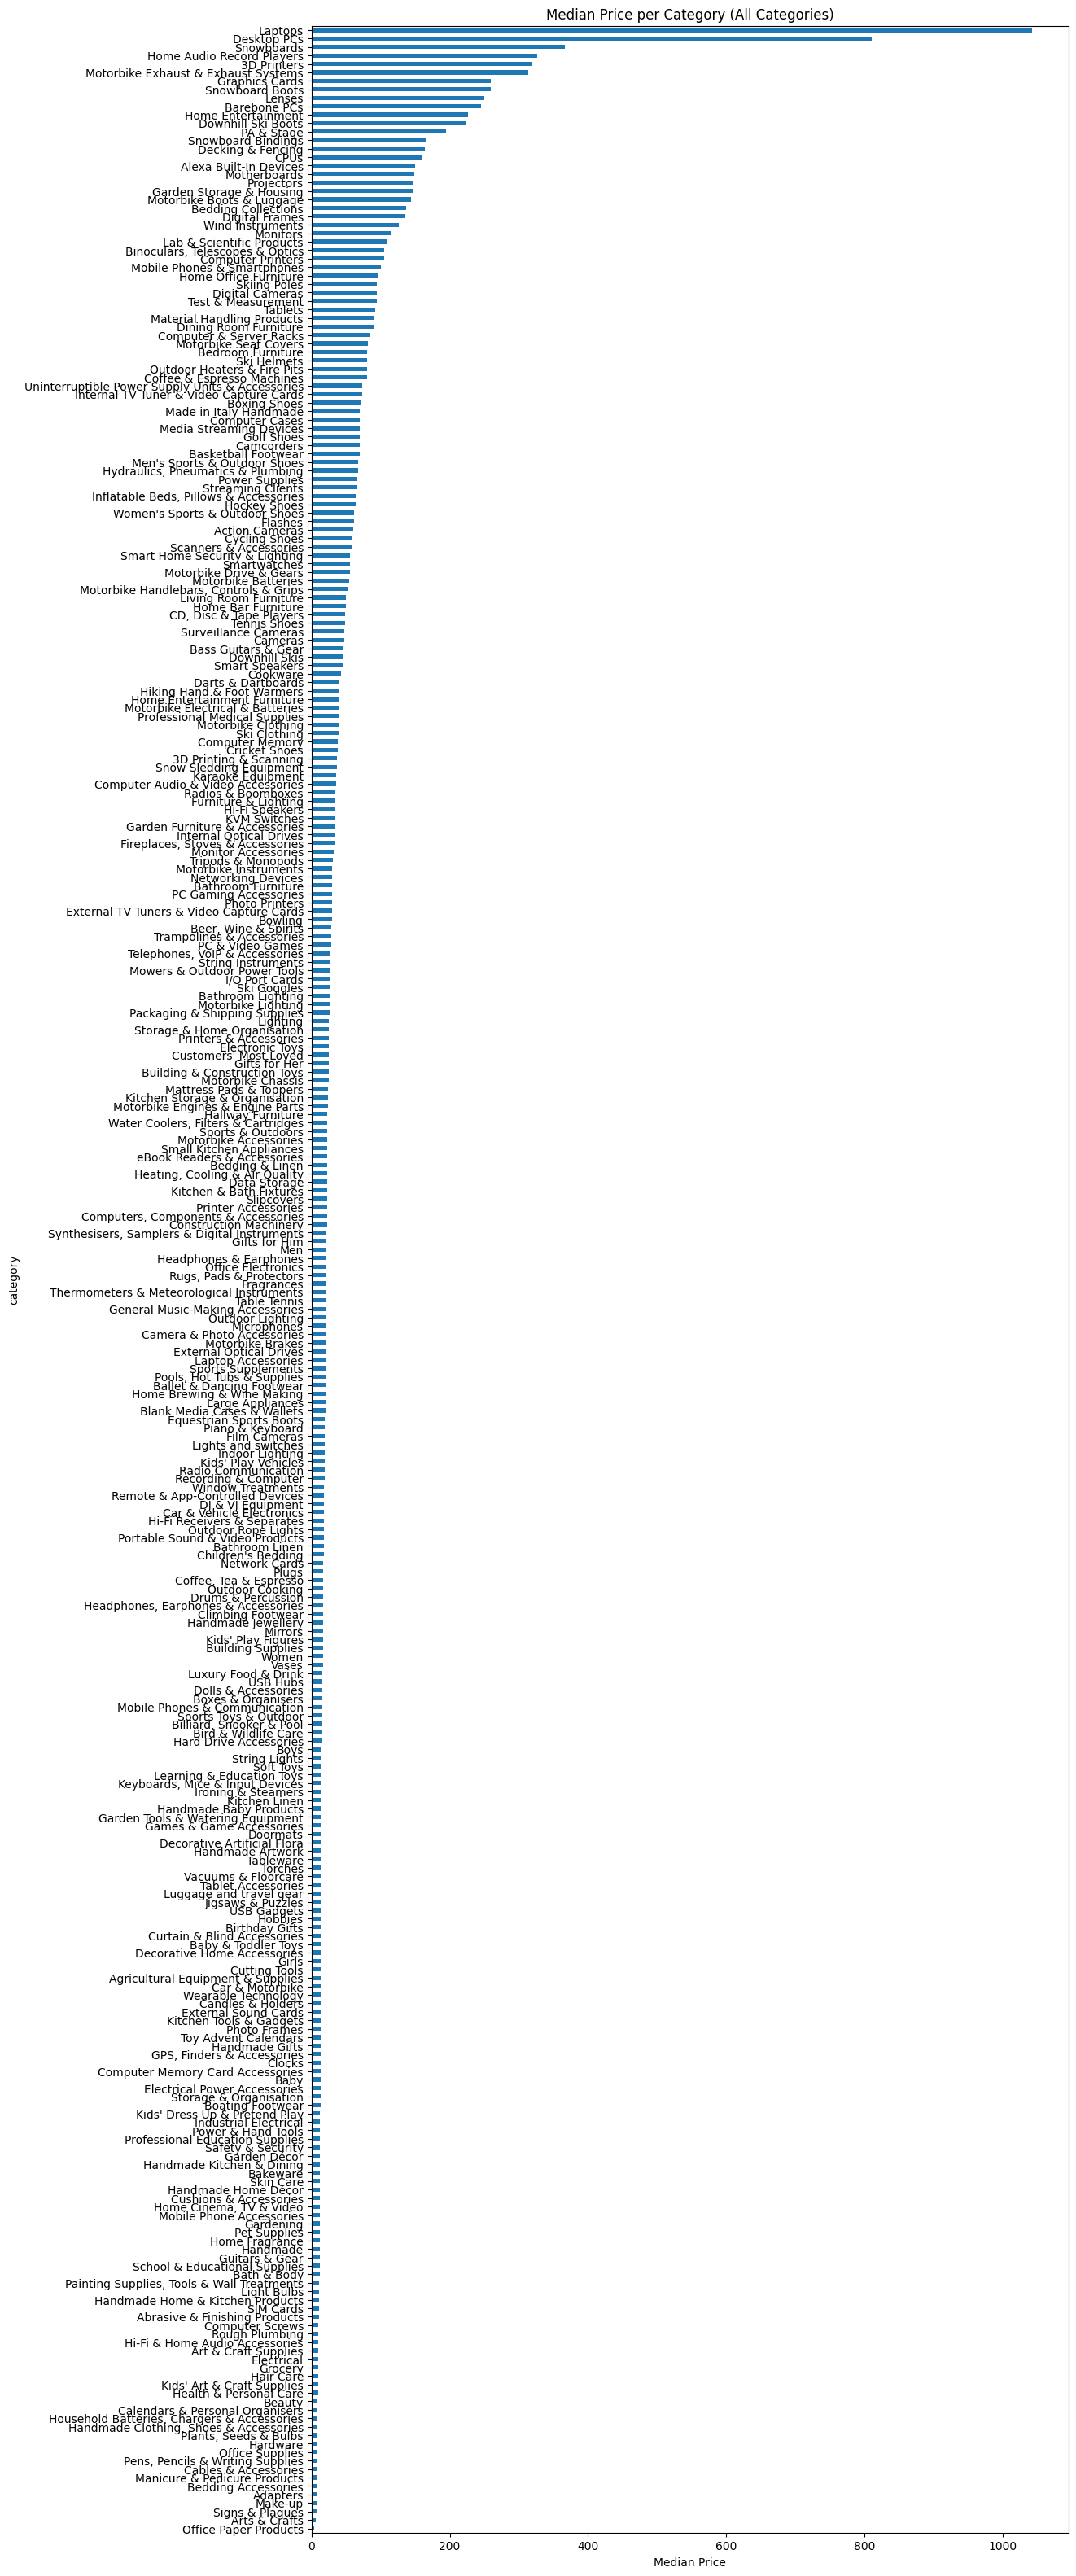

In [ ]:
# Which product category tends to have the highest median price? Don't filter here by top categories.

medians = df.groupby("category")["price"].median().sort_values()

plt.figure(figsize=(12, 40))  # alargado en vertical
medians.plot(kind="barh")
plt.title("Median Price per Category (All Categories)")
plt.xlabel("Median Price")
plt.show()

#Plotting a violin or box plot with 300+ categorical levels results in an unreadable visualization.
#To satisfy the requirement of not filtering categories while still enabling interpretation,
#I used an aggregated summary plot (median/mean per category), which preserves ALL categories but produces a readable analysis.


C:\Users\elbgr\AppData\Local\Temp\ipykernel_5000\4018717679.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_top_prod, x='title', y='price', palette="pink")
C:\Users\elbgr\AppData\Local\Temp\ipykernel_5000\4018717679.py:10: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


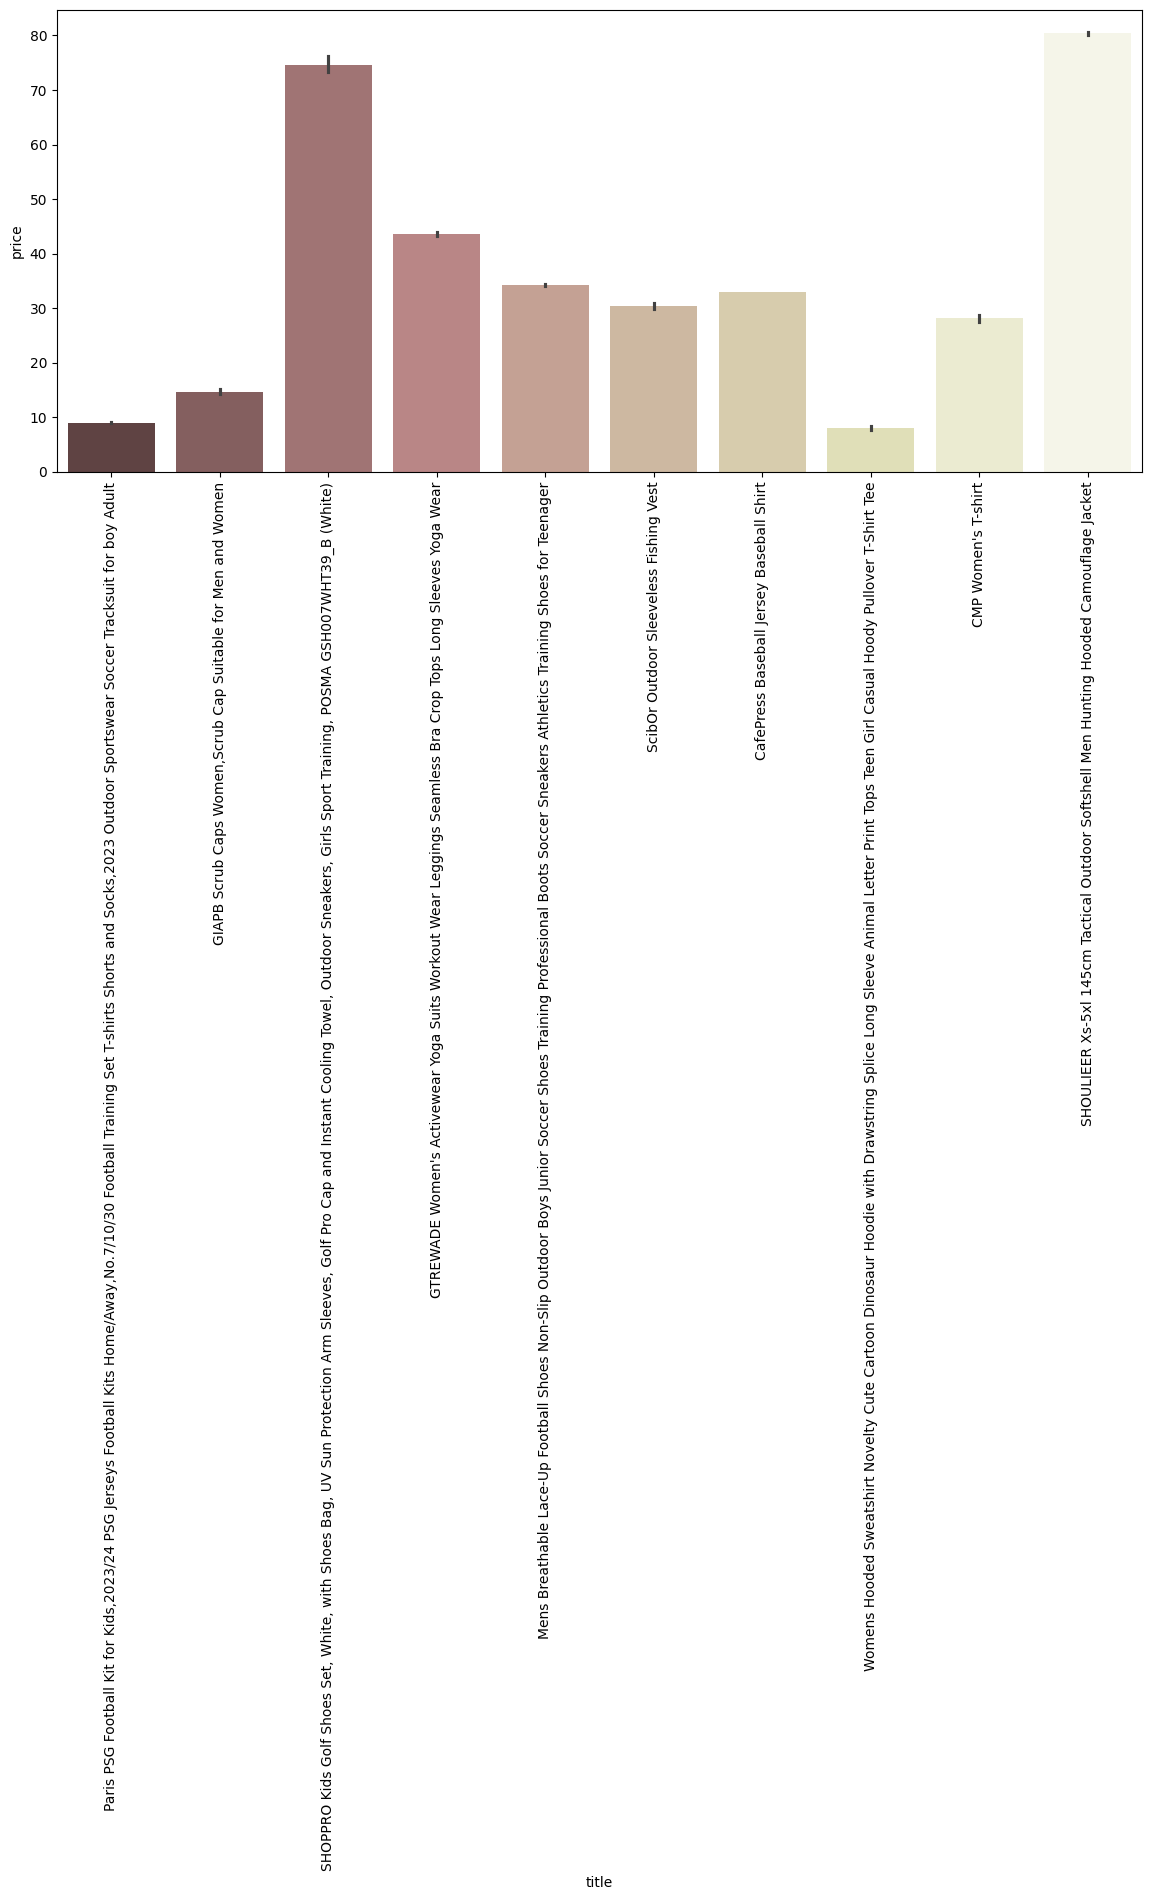

In [17]:
#Bar Charts:

top_products=df_no_outliers['title'].value_counts().head(10).index

df_top_prod = df_no_outliers[df_no_outliers['title'].isin(top_products)]

plt.figure(figsize=(14, 6))
sns.barplot(data=df_top_prod, x='title', y='price', palette="pink")
plt.xticks(rotation=90)
plt.tight_layout()   
plt.show()


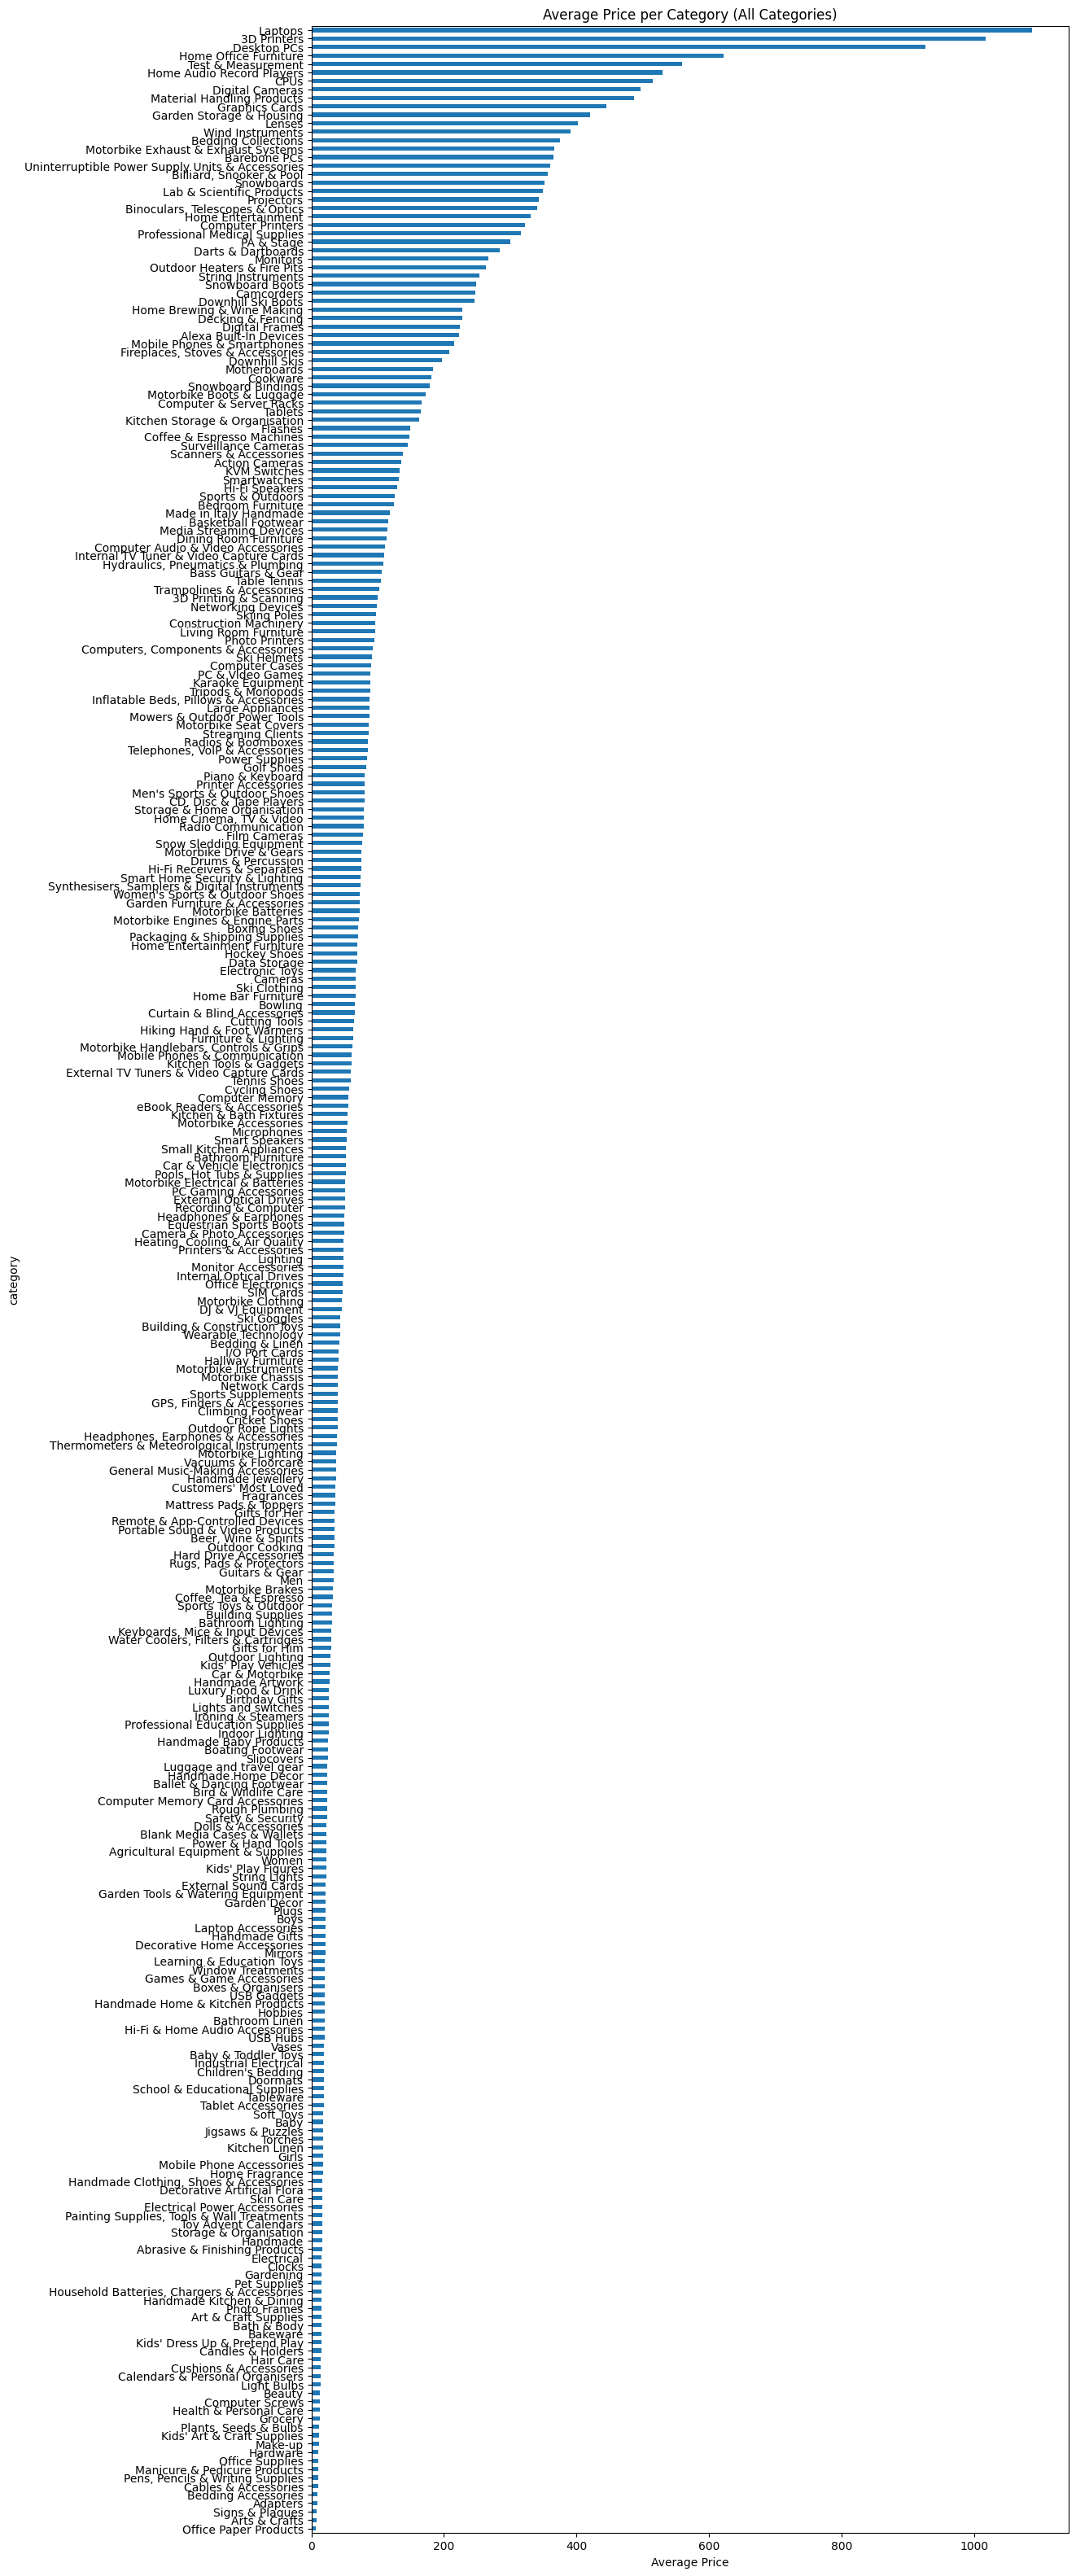

In [26]:
#Which product category commands the highest average price? Don't filter here by top categories.

average = df.groupby("category")["price"].mean().sort_values()

plt.figure(figsize=(12, 40))  # alargado en vertical
average.plot(kind="barh")
plt.title("Average Price per Category (All Categories)")
plt.xlabel("Average Price")
plt.show()

C:\Users\elbgr\AppData\Local\Temp\ipykernel_5000\44246922.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top_cat, x='category', y='stars', palette="pastel")


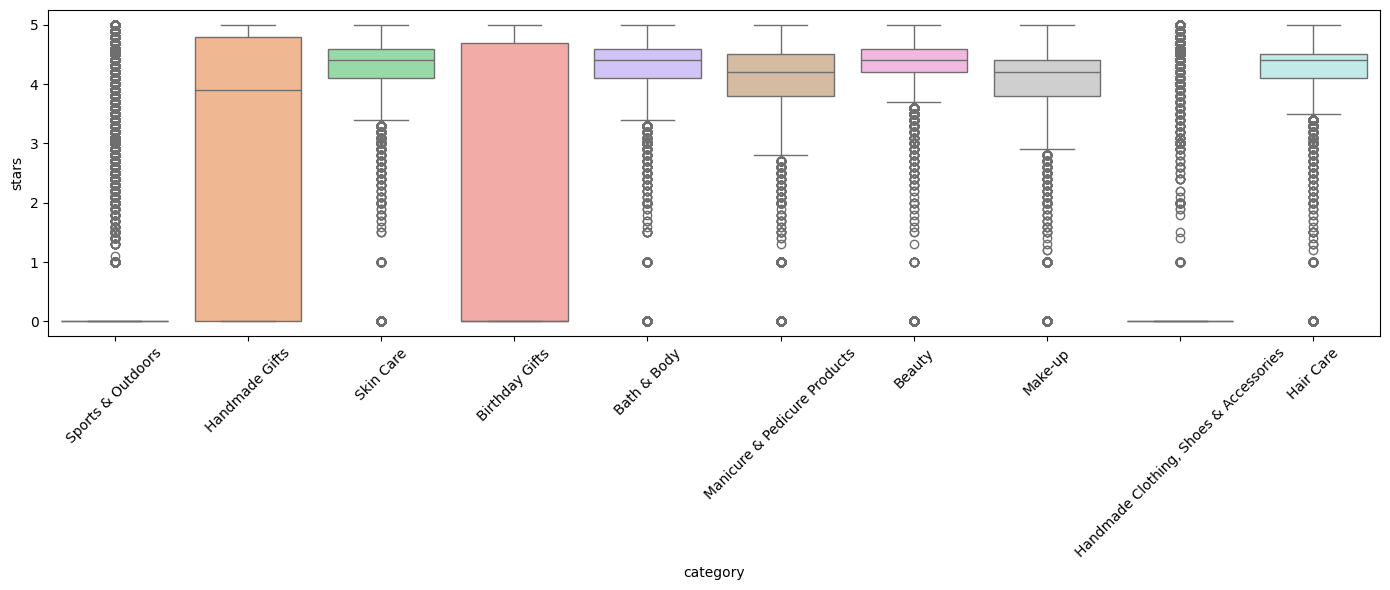

In [29]:
#Box Plots:


top_categories = df_no_outliers['category'].value_counts().head(10).index


df_top_cat = df_no_outliers[df_no_outliers['category'].isin(top_categories)]


plt.figure(figsize=(14, 6))
sns.boxplot(data=df_top_cat, x='category', y='stars', palette="pastel")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



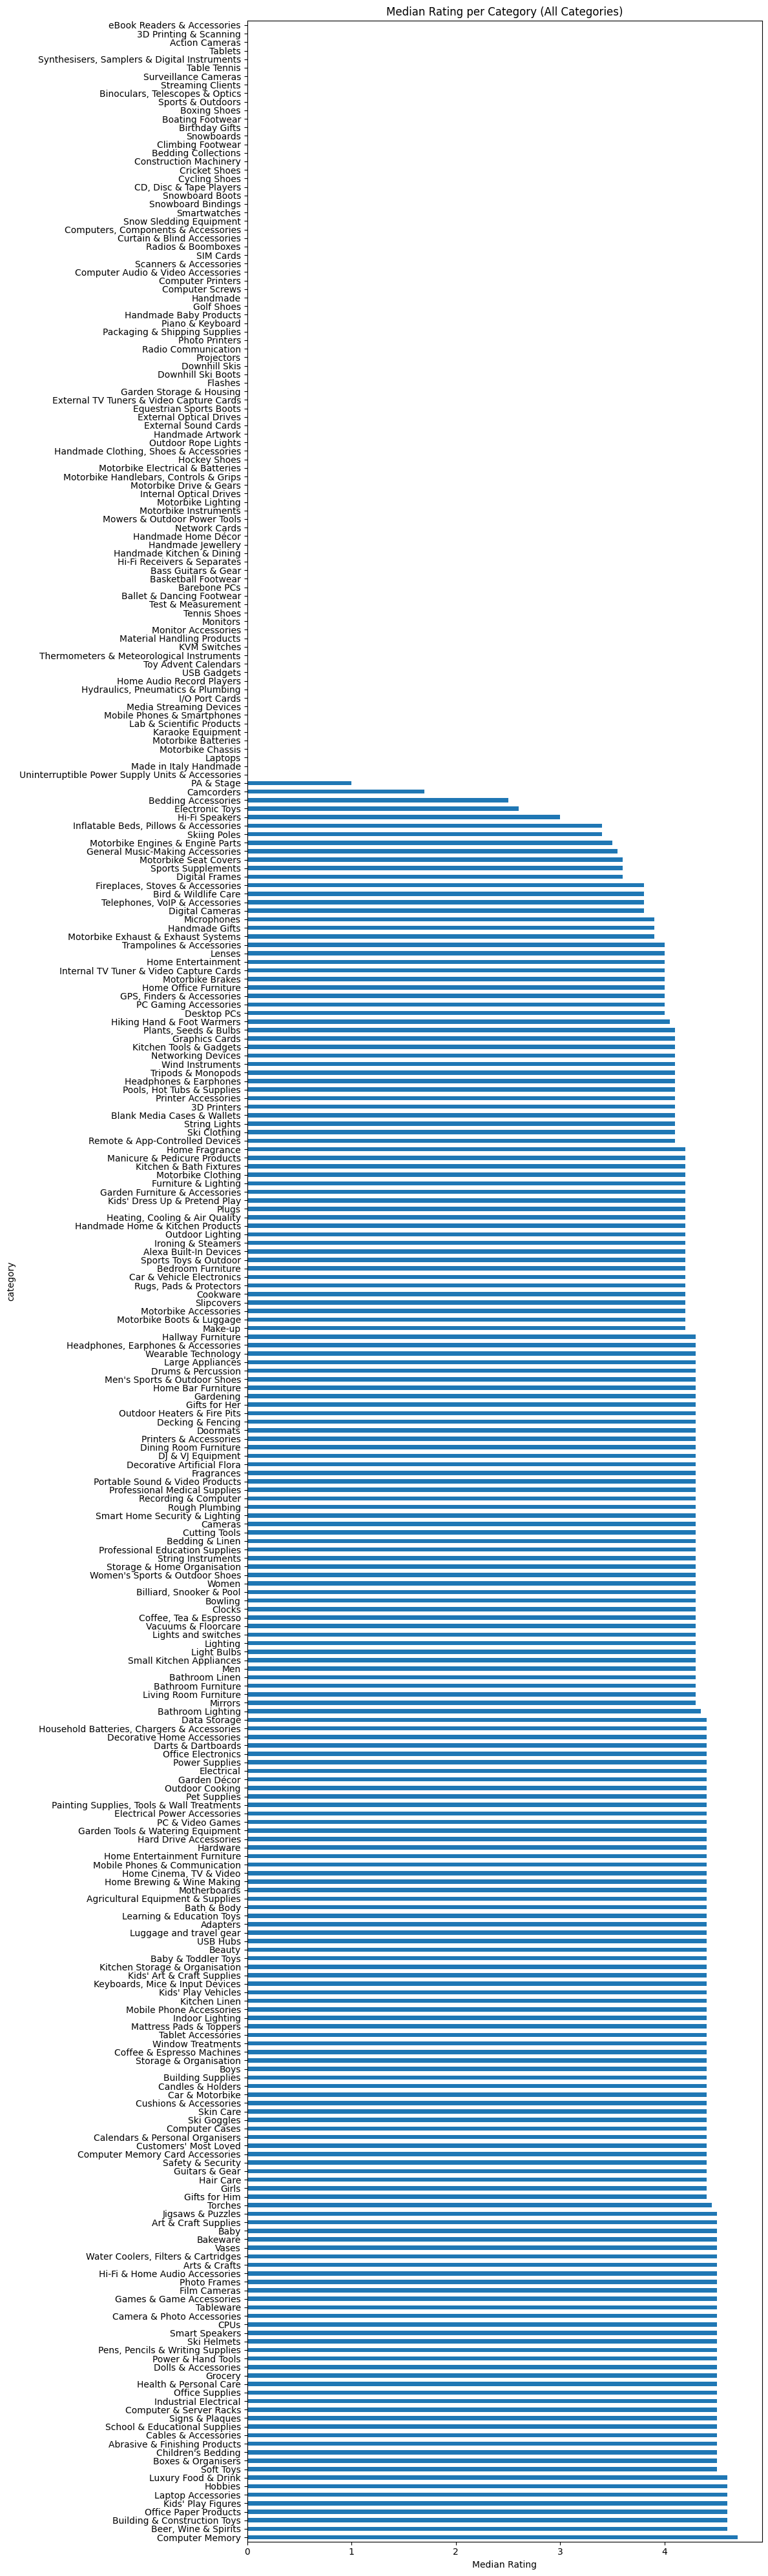

In [30]:
median_ratings = (
    df_no_outliers
    .groupby('category')['stars']
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 40))
median_ratings.plot(kind='barh')
plt.xlabel('Median Rating')
plt.title('Median Rating per Category (All Categories)')
plt.tight_layout()
plt.show()


## **Part 3:** Investigating the Interplay Between Product Prices and Ratings

**Objective:** Analyze how product ratings (stars) correlate with product prices.

**1.Correlation Coefficients:**

Calculate the correlation coefficient between price and stars.
Is there a significant correlation between product price and its rating?

**2.Visualizations:**

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.
Examine if product prices typically follow a normal distribution using a QQ plot.

In [19]:
#1.Correlation Coefficients:

correlation = df['price'].corr(df['stars'])
correlation

np.float64(-0.12490673262148386)

C:\Users\elbgr\AppData\Local\Temp\ipykernel_5000\946606370.py:4: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=df_no_outliers, x='stars', y='price', palette="colorblind")


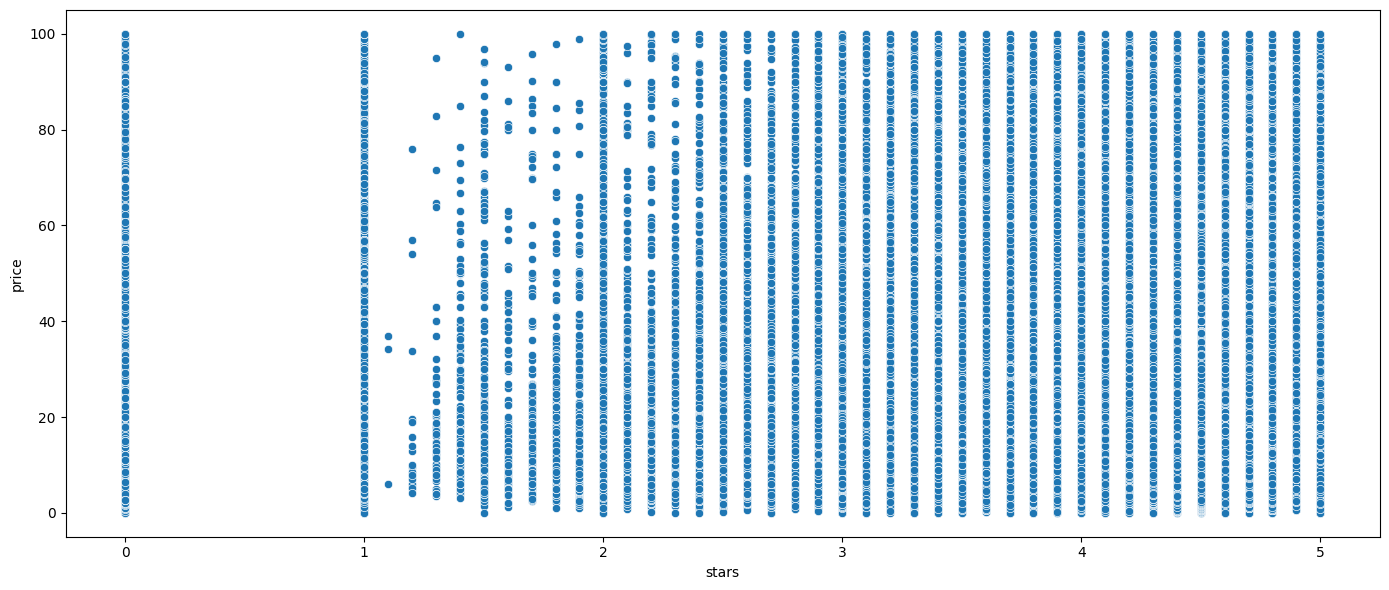

In [20]:
#2.Visualizations:

plt.figure(figsize=(14, 6))
sns.scatterplot(data=df_no_outliers, x='stars', y='price', palette="colorblind")
plt.tight_layout()   
plt.show()

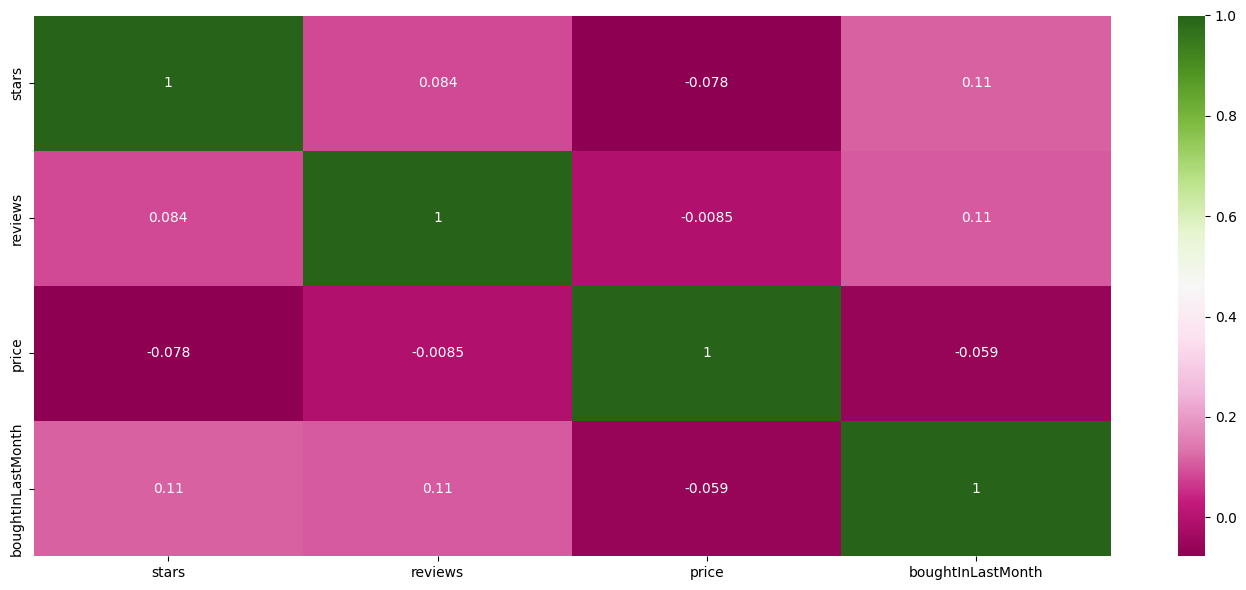

In [21]:
df_numerical=df_no_outliers.select_dtypes(include='number')

correlation_matrix=df_numerical.corr()

plt.figure(figsize=(14, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="PiYG")
plt.tight_layout()   
plt.show()



In [32]:
!python -m pip install statsmodels


   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ---------- ----------------------------- 2.6/9.6 MB 13.4 MB/s eta 0:00:01
   ----------------------------- ---------- 7.1/9.6 MB 17.3 MB/s eta 0:00:01
   ---------------------------------------- 9.6/9.6 MB 18.2 MB/s  0:00:00

   ---------------------------------------- 0/2 [patsy]
   ---------------------------------------- 0/2 [patsy]
   ---------------------------------------- 0/2 [patsy]
   ---------------------------------------- 0/2 [patsy]
   ---------------------------------------- 0/2 [patsy]
   ---------------------------------------- 0/2 [patsy]
   -------------------- ------------------- 1/2 [statsmodels]
   -------------------- ------------------- 1/2 [statsmodels]
   -------------------- ------------------- 1/2 [statsmodels]
   -------------------- ------------------- 1/2 [statsmodels]
   -------------------- ------------------- 1/2 [statsmodels]
   -------------------- ------------------- 1/2 [statsmo


[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


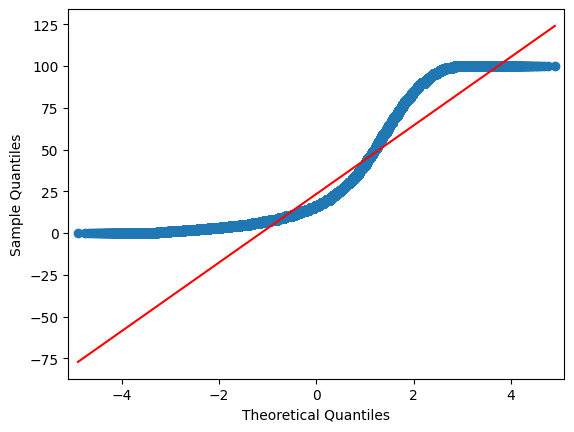

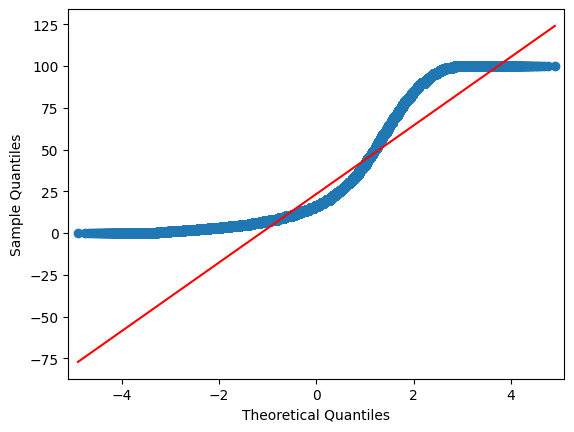

In [34]:
import statsmodels.api as sm

sm.qqplot(df_no_outliers['price'], line='s')

## **Business-centric report**

The chi-square test indicates a statistically significant association between product category and bestseller status.
However, Cramer’s V = 0.12 suggests that the strength of this association is weak.

This means that while some categories indeed contain more bestsellers than the rest (aprox 6%) the product category explains only a small portion of the variability in bestseller occurrence.

The category Laptops has the highest median and average price.

Computer memory tends to have the highest median rating from customers.

The correlation between price and customer ratings is weak and negative (r = –0.12).
This suggests that higher-priced products tend to receive slightly lower ratings,
but the relationship is very weak and not practically meaningful.

Price does not follow a normal distribution, as indicated by the Q-Q plot, which shows strong right skew and heavy tails





